# 第 35 课｜时间索引与 OHLCV 重采样

本 Notebook 对应「365 天量化金融」第 35 课。课程代码主线来自本地视频、课件截图和 Whisper 口播整理；在此基础上补充量化数据语义、断言、性能验证和方法边界。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/35_youtube-TNDtFf1FePM/index.html`
- 环境：`pkm-quant`
- 数据：固定随机种子生成的离线模拟行情（**非真实股票数据**）
- 状态：可运行学习稿；不代表策略收益承诺

> **数据声明**：本 Notebook 的证券名称、价格和成交量均为教学模拟数据。它用于稳定复现计算方法，不能用于评价真实证券、市场规律或策略收益。

## 本节量化问题

本实验读取 1 个模拟标的、10 个交易日、每天 48 根的 5 分钟行情，依次完成：

1. 观察原始时间文本及其显式 `+08:00` 偏移；
2. 把同一时刻规范化为 UTC，再转换回 `Asia/Shanghai` 显示；
3. 建立有序、唯一的 `DatetimeIndex`，按本地日期选择数据；
4. 按字段语义把 5 分钟 OHLCV 和成交额聚合到自然日；
5. 用成交额/成交量计算日 VWAP，并从原始 bar 手工复核；
6. 区分普通工作日偏移与带休市表的交易日历。

原始表 shape 为 `(480, 8)`；时间列提升为索引后，`bars` shape 为 `(480, 7)`；最终日频表 shape 为 `(10, 7)`。

本教学数据把 `timestamp` 解释为 5 分钟 bar 的**结束时刻**，例如 `09:35` 表示从开盘后第一段 5 分钟形成的 bar。真实数据必须查阅供应商文档，确认时间戳究竟代表开始、结束还是撮合时刻。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


## 先看原始 5 分钟数据

原始表每行是一根 5 分钟 K 线。先不要转换时间：直接观察 `timestamp` 的文本形式、字段和 dtype，确认源文本已经包含 `+08:00` 时区偏移。

In [2]:
# 原样读取 CSV，先展示尚未转换的时间文本和 8 个原始字段。
raw_bars = pd.read_csv(DATA_DIR / "intraday_5m.csv")
print("raw_bars.shape =", raw_bars.shape)
print("原始列 =", raw_bars.columns.tolist())
print("timestamp dtype =", raw_bars["timestamp"].dtype)
print("首条时间文本 =", raw_bars.loc[0, "timestamp"])

assert raw_bars.shape == (480, 8)
assert raw_bars["symbol"].nunique() == 1
raw_bars.head()

raw_bars.shape = (480, 8)
原始列 = ['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume', 'amount']
timestamp dtype = str
首条时间文本 = 2025-03-03T09:35:00+08:00


,timestamp,symbol,open,high,low,close,volume,amount
0,2025-03-03T09:35:00+08:00,SYNTH_A,100.0000,100.0287,99.8453,99.8740,70004,6994518.30
1,2025-03-03T09:40:00+08:00,SYNTH_A,99.8740,99.9521,99.8213,99.8994,27487,2745701.86
2,2025-03-03T09:45:00+08:00,SYNTH_A,99.8994,100.0241,99.8560,99.9807,17711,1770278.37
3,2025-03-03T09:50:00+08:00,SYNTH_A,99.9807,100.1380,99.9112,100.0684,54658,5467943.28
4,2025-03-03T09:55:00+08:00,SYNTH_A,100.0684,100.1493,99.9351,100.0159,42810,4282429.97


### 将带偏移时间规范化为 UTC，再转换为上海显示

源字符串已经带 `+08:00`。`pd.to_datetime(..., utc=True, errors="raise")` 会解析其中的偏移，并把同一绝对时刻统一表示为 UTC；`.dt.tz_convert("Asia/Shanghai")` 保持绝对时刻不变，只改变当地显示。

第一条记录可以直接核对：

- 源文本：`2025-03-03T09:35:00+08:00`
- UTC：`2025-03-03 01:35:00+00:00`
- 上海：`2025-03-03 09:35:00+08:00`

如果真实输入是不带时区的上海钟表时间，不能直接用 `utc=True` 假定它属于 UTC；应先解析为 naive 时间，再按来源时区 `tz_localize("Asia/Shanghai")`。

In [3]:
# 同时保留源文本、UTC 表示和上海表示，观察同一时刻的三种写法。
parsed_utc = pd.to_datetime(
    raw_bars["timestamp"],
    utc=True,
    errors="raise",
)
shanghai_time = parsed_utc.dt.tz_convert("Asia/Shanghai")

timestamp_preview = pd.DataFrame(
    {
        "source_text": raw_bars["timestamp"].head(3),
        "parsed_utc": parsed_utc.head(3),
        "Asia/Shanghai": shanghai_time.head(3),
    }
)
assert str(parsed_utc.dt.tz) == "UTC"
assert str(shanghai_time.dt.tz) == "Asia/Shanghai"
timestamp_preview

,source_text,parsed_utc,Asia/Shanghai
0,2025-03-03T09:35:00+08:00,2025-03-03 01:35:00+00:00,2025-03-03 09:35:00+08:00
1,2025-03-03T09:40:00+08:00,2025-03-03 01:40:00+00:00,2025-03-03 09:40:00+08:00
2,2025-03-03T09:45:00+08:00,2025-03-03 01:45:00+00:00,2025-03-03 09:45:00+08:00


### 建立有序的 DatetimeIndex

`set_index("timestamp")` 把时间列提升为行索引，所以数据列由 8 列变为 7 列；`sort_index()` 保证时间升序。后续 `first`、`last` 和部分字符串切片都依赖正确的时间顺序。

本例只有一个标的，因此时间戳本身唯一。多标的数据中，不同股票可以共享时间戳，应检查 `(timestamp, symbol)` 联合键，而不是要求 DatetimeIndex 单独唯一。

In [4]:
# 用上海时间建立索引，并验证单标的教学数据的时间顺序和唯一性。
bars = raw_bars.assign(timestamp=shanghai_time)
bars = bars.set_index("timestamp").sort_index()

assert isinstance(bars.index, pd.DatetimeIndex)
assert str(bars.index.tz) == "Asia/Shanghai"
assert bars["symbol"].nunique() == 1
assert bars.index.is_monotonic_increasing and bars.index.is_unique
assert bars.shape == (480, 7)
print("bars.shape =", bars.shape)
print("时间区间 =", bars.index.min(), "→", bars.index.max())
bars.head()

bars.shape = (480, 7)
时间区间 = 2025-03-03 09:35:00+08:00 → 2025-03-14 15:00:00+08:00


,symbol,open,high,low,close,volume,amount
timestamp,,,,,,,
2025-03-03 09:35:00+08:00,SYNTH_A,100.0000,100.0287,99.8453,99.8740,70004,6994518.30
2025-03-03 09:40:00+08:00,SYNTH_A,99.8740,99.9521,99.8213,99.8994,27487,2745701.86
2025-03-03 09:45:00+08:00,SYNTH_A,99.8994,100.0241,99.8560,99.9807,17711,1770278.37
2025-03-03 09:50:00+08:00,SYNTH_A,99.9807,100.1380,99.9112,100.0684,54658,5467943.28
2025-03-03 09:55:00+08:00,SYNTH_A,100.0684,100.1493,99.9351,100.0159,42810,4282429.97


## 课程示例 1：部分字符串索引和时间属性

### 1.1 按索引所在时区选择一个本地日期

`bars.loc["2025-03-03"]` 是 DatetimeIndex 的部分字符串标签选择，返回上海时区中这一个本地日期的全部记录。本例一天有 48 根 bar，第一根标记为 `09:35`，最后一根标记为 `15:00`。

In [5]:
# 选择上海本地日期 2025-03-03，并展示数量和首尾时间。
one_day = bars.loc["2025-03-03"]

assert len(one_day) == 48
assert one_day.index[0].strftime("%H:%M") == "09:35"
assert one_day.index[-1].strftime("%H:%M") == "15:00"

one_day_summary = pd.Series(
    {
        "bar_count": len(one_day),
        "first_bar": one_day.index[0],
        "last_bar": one_day.index[-1],
    },
    name="value",
)
one_day_summary.to_frame()

,value
bar_count,48
first_bar,2025-03-03 09:35:00+08:00
last_bar,2025-03-03 15:00:00+08:00


### 1.2 从 DatetimeIndex 提取小时

`.index.hour` 为每根 bar 返回当地小时；`groupby(...).size()` 再统计各小时包含多少条记录。结果中没有 12 点，是因为教学数据模拟了午间休市。

In [6]:
# 按上海当地小时统计 bar 数量，保留 hour 标签便于核对交易时段。
hour_counts = (
    one_day.groupby(one_day.index.hour)
    .size()
    .rename("bar_count")
)
hour_counts.index.name = "hour"
assert hour_counts.sum() == 48
hour_counts.to_frame()

,bar_count
hour,
9,5
10,12
11,7
13,11
14,12
15,1


## 课程示例 2：按字段语义聚合 OHLCV

### 2.1 先按自然日聚合 OHLCV 和成交额

`resample("1D", closed="left", label="left")` 在索引的 `Asia/Shanghai` 时区按自然日分桶：

- `closed="left"`：左边界属于当前桶；
- `label="left"`：用当天 `00:00` 标记结果；
- `open="first"`、`high="max"`、`low="min"`、`close="last"`；
- `volume="sum"`、`amount="sum"`。

`first/last` 依赖前面已经按时间排序。自然日重采样会产生周末空桶，本样本从 12 个自然日桶中用 `dropna(subset=["open"])` 删除 2 个无交易周末，留下 10 个交易日。

当前代码明确只处理一个标的；若 `symbol` 多于一个，必须先按 `symbol` 分组，否则不同证券会被聚合进同一根日 K 线。

In [7]:
# 为每个字段指定符合日 K 线语义的聚合规则。
assert bars["symbol"].nunique() == 1, "当前示例只适用于单标的"
aggregation = {
    "open": "first",
    "high": "max",
    "low": "min",
    "close": "last",
    "volume": "sum",
    "amount": "sum",
}
calendar_daily = bars.resample(
    "1D",
    closed="left",
    label="left",
).agg(aggregation)

daily_ohlcv = calendar_daily.dropna(subset=["open"]).copy()
assert len(calendar_daily) == 12
assert daily_ohlcv.shape == (10, 6)
print("自然日桶 =", len(calendar_daily), "；有交易日 =", len(daily_ohlcv))
daily_ohlcv.head(3)

自然日桶 = 12 ；有交易日 = 10


,open,high,low,close,volume,amount
timestamp,,,,,,
2025-03-03 00:00:00+08:00,100.0000,102.0483,99.4513,101.4567,1560695,1.570121e+08
2025-03-04 00:00:00+08:00,101.4567,102.7851,101.2905,102.5536,1672999,1.707269e+08
2025-03-05 00:00:00+08:00,102.5536,102.6851,101.2577,101.7882,1942279,1.976547e+08


### 2.2 用成交额除以成交量计算日 VWAP

日 VWAP 使用整个日桶的总成交额除以总成交量：

> `daily_vwap = sum(amount) / sum(volume)`

除法前先检查成交量大于 0，避免得到无意义的无穷大。本模拟数据的 `amount` 来自每根 bar 的典型价格乘成交量，因此这里只验证聚合公式；它不是逐笔成交数据推导出的真实市场 VWAP。

In [8]:
# 在日频 OHLCV 表上增加 VWAP，并展示公式中的两个输入和结果。
assert daily_ohlcv["volume"].gt(0).all()

daily_bars = daily_ohlcv.copy()
daily_bars.loc[:, "vwap"] = (
    daily_bars["amount"] / daily_bars["volume"]
)

assert daily_bars.shape == (10, 7)
daily_bars[["amount", "volume", "vwap"]].head(3)

,amount,volume,vwap
timestamp,,,
2025-03-03 00:00:00+08:00,1.570121e+08,1560695,100.603947
2025-03-04 00:00:00+08:00,1.707269e+08,1672999,102.048446
2025-03-05 00:00:00+08:00,1.976547e+08,1942279,101.764336


### 2.3 从原始 5 分钟 bar 手工复核第一天

重新从 `2025-03-03` 的 48 根 bar 计算每个字段，再与 `daily_bars` 的第一行逐项比较。断言验证数值，带字段标签的表格负责让人直接核对。

In [9]:
# 独立计算首个交易日的 OHLCV、成交额和 VWAP，再与重采样结果比较。
sample_date = daily_bars.index[0]
sample_minutes = bars.loc[sample_date.strftime("%Y-%m-%d")]

manual_values = pd.Series(
    {
        "open": sample_minutes["open"].iloc[0],
        "high": sample_minutes["high"].max(),
        "low": sample_minutes["low"].min(),
        "close": sample_minutes["close"].iloc[-1],
        "volume": sample_minutes["volume"].sum(),
        "amount": sample_minutes["amount"].sum(),
        "vwap": (
            sample_minutes["amount"].sum()
            / sample_minutes["volume"].sum()
        ),
    },
    name="manual_from_5m",
)
resampled_values = (
    daily_bars.loc[sample_date, manual_values.index]
    .astype(float)
    .rename("resampled")
)
manual_check = pd.concat(
    [manual_values, resampled_values],
    axis=1,
)
manual_check.loc[:, "abs_difference"] = (
    manual_check["manual_from_5m"] - manual_check["resampled"]
).abs()

np.testing.assert_allclose(
    manual_check["manual_from_5m"].to_numpy(dtype=float),
    manual_check["resampled"].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-12,
)
print("手工校验日期 =", sample_date.date(), "；bar 数 =", len(sample_minutes))
manual_check.round(6)

手工校验日期 = 2025-03-03 ；bar 数 = 48


,manual_from_5m,resampled,abs_difference
open,1.000000e+02,1.000000e+02,0.0
high,1.020483e+02,1.020483e+02,0.0
low,9.945130e+01,9.945130e+01,0.0
close,1.014567e+02,1.014567e+02,0.0
volume,1.560695e+06,1.560695e+06,0.0
amount,1.570121e+08,1.570121e+08,0.0
vwap,1.006039e+02,1.006039e+02,0.0


## 失败示例：把平均每根 bar 成交量误当成日成交量

`mean(volume)` 本身不是数学错误，它表示“平均每根 5 分钟 bar 的成交量”；错误是把这个统计量解释为“全日成交量”。对于每天恰好 48 根的完整样本：

> 日成交量总和 ÷ 平均每根 bar 成交量 = 48

因此日总量必须用 `sum`，而不是一刀切对所有字段调用 `mean`。

In [10]:
# 对比日成交量总和、平均 bar 成交量和真实 bar 数量。
mean_by_day = bars.resample(
    "1D",
    closed="left",
    label="left",
).mean(numeric_only=True)
bar_count = bars["volume"].resample(
    "1D",
    closed="left",
    label="left",
).count()

volume_comparison = pd.DataFrame(
    {
        "daily_volume_sum": daily_bars["volume"],
        "mean_5m_bar_volume": mean_by_day.loc[daily_bars.index, "volume"],
        "actual_bar_count": bar_count.loc[daily_bars.index],
    }
)
volume_comparison.loc[:, "sum_div_mean"] = (
    volume_comparison["daily_volume_sum"]
    / volume_comparison["mean_5m_bar_volume"]
)

np.testing.assert_allclose(
    volume_comparison["sum_div_mean"],
    volume_comparison["actual_bar_count"],
)
volume_comparison.head(3).round(6)

,daily_volume_sum,mean_5m_bar_volume,actual_bar_count,sum_div_mean
timestamp,,,,
2025-03-03 00:00:00+08:00,1560695,32514.479167,48,48.0
2025-03-04 00:00:00+08:00,1672999,34854.145833,48,48.0
2025-03-05 00:00:00+08:00,1942279,40464.145833,48,48.0


## 课程示例 3：`tz_localize` 与 `tz_convert`

naive Timestamp 只有钟表时间，还没有对应的绝对时刻：

- `tz_localize("Asia/Shanghai")` 按上海地区解释这个钟表时间，从而确定一个绝对时刻；
- `tz_convert("America/New_York")` 保持 UTC 时刻不变，只改变当地显示。

纽约结果显示为前一天不是错误。对于有夏令时切换的地区，本地化还要根据数据语义处理 `ambiguous` 和 `nonexistent` 时刻。

In [11]:
# 把上海当地钟表时间确定为一个时刻，再转换到纽约和 UTC 显示。
naive = pd.Timestamp("2025-03-03 09:35:00")
shanghai = naive.tz_localize("Asia/Shanghai")
new_york = shanghai.tz_convert("America/New_York")

assert shanghai.tz_convert("UTC") == new_york.tz_convert("UTC")
timezone_demo = pd.Series(
    {
        "naive（无绝对时刻）": str(naive),
        "localized_shanghai": str(shanghai),
        "converted_new_york": str(new_york),
        "same_instant_utc": str(shanghai.tz_convert("UTC")),
    },
    name="value",
)
timezone_demo.to_frame()

,value
naive（无绝对时刻）,2025-03-03 09:35:00
localized_shanghai,2025-03-03 09:35:00+08:00
converted_new_york,2025-03-02 20:35:00-05:00
same_instant_utc,2025-03-03 01:35:00+00:00


## 工作日偏移不等于交易日历

`BDay` 只编码周一到周五，不知道交易所休市、临时停市或补班规则。下面声明一个纯教学休市日 `2025-03-04`：

- 普通 `BDay(1)` 仍返回 3 月 4 日；
- `CustomBusinessDay` 收到这张休市表后跳到 3 月 5 日。

`CustomBusinessDay` 也只和传入的日历一样可靠；生产研究应使用版本化、可追溯的官方交易所日历。

In [12]:
# 用显式声明的教学休市日，对比普通工作日和自定义业务日。
from pandas.tseries.offsets import BDay, CustomBusinessDay

calendar_start = pd.Timestamp("2025-03-03")
declared_closure = pd.Timestamp("2025-03-04")
plain_bday_result = calendar_start + BDay(1)
custom_bday_result = calendar_start + CustomBusinessDay(
    holidays=[declared_closure]
)

assert plain_bday_result == pd.Timestamp("2025-03-04")
assert custom_bday_result == pd.Timestamp("2025-03-05")
pd.Series(
    {
        "起始日": calendar_start.date(),
        "声明休市日": declared_closure.date(),
        "普通 BDay(1)": plain_bday_result.date(),
        "CustomBusinessDay(1)": custom_bday_result.date(),
    },
    name="date",
).to_frame()

,date
起始日,2025-03-03
声明休市日,2025-03-04
普通 BDay(1),2025-03-04
CustomBusinessDay(1),2025-03-05


## 可视化日成交量

把日成交量除以 `1_000_000` 后，以“百万模拟单位”为纵轴，避免图中出现难读的大整数。横轴使用交易日字符串，因此 10 个交易日等距排列，周末不会按两个自然日的宽度留空。

柱顶数值用于准确读取，图形用于比较相对高低；输出保存到 `outputs/35_daily_volume.png`。

图表已保存： /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain/outputs/35_daily_volume.png


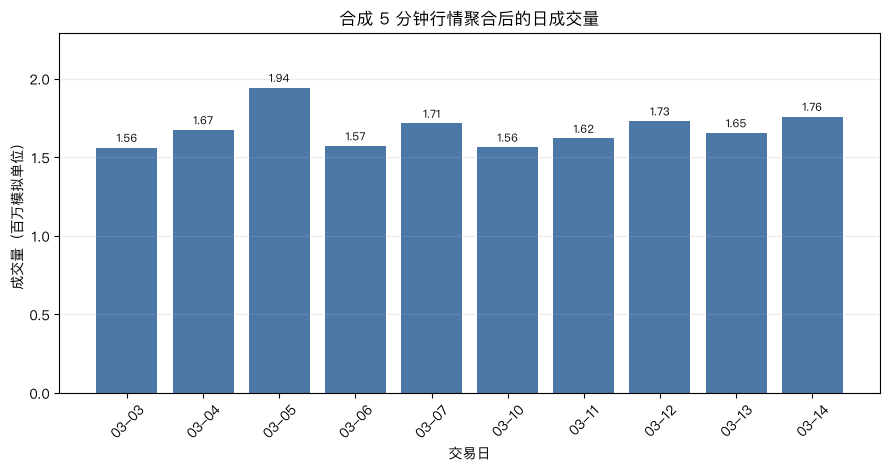

In [13]:
# 用百万模拟单位绘制带数值标注的日成交量柱状图。
daily_volume_million = daily_bars["volume"] / 1_000_000
fig, ax = plt.subplots(figsize=(9, 4.8))
bar_artists = ax.bar(
    daily_bars.index.strftime("%m-%d"),
    daily_volume_million,
    color="#4C78A8",
)
ax.set_title("合成 5 分钟行情聚合后的日成交量")
ax.set_xlabel("交易日")
ax.set_ylabel("成交量（百万模拟单位）")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_ylim(0, daily_volume_million.max() * 1.18)
ax.bar_label(
    bar_artists,
    fmt="%.2f",
    padding=3,
    fontsize=8,
)
fig.tight_layout()
chart_path = OUTPUT_DIR / "35_daily_volume.png"
fig.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight",
)
print("图表已保存：", chart_path)
plt.show()

## 方法边界

- 时间戳必须声明代表 bar 起点、终点还是撮合时刻；错误约定会造成整段信号错位。
- `first/last` 只对已经按时间排序的数据有正确语义。
- 多标的数据必须先按 `symbol` 分组；联合键 `(timestamp, symbol)` 应唯一。
- 重采样前要检测缺 bar、重复 bar、半日交易和零成交量，不能只依赖固定的 48 根断言。
- 自然日重采样只适用于此处白天交易样例；期货夜盘、加密资产和跨时区资产需要显式交易日映射。
- OHLCV 只保留桶内摘要，无法恢复真实成交顺序。
- VWAP 使用总成交额/总成交量；简单平均分钟价格不是 VWAP，模拟 bar 成交额也不等同于逐笔成交数据。
- `BDay` 不是交易所日历；任何自定义休市表都必须记录来源和版本。

## 可复用结论与练习

**可复用结论**

1. 先展示原始时间文本，再决定解析、localize 或 convert，不能猜测来源时区。
2. 重采样规则由字段语义决定：OHLC、成交量和成交额不能使用同一个聚合函数。
3. 聚合结果应选一天回到原始 bar 手工复核，而不是只看代码能运行。
4. 自然日、工作日和交易日是三种不同概念。

**练习**

- 删除 `2025-03-03` 的一根 5 分钟 bar，先用 bar count 检测异常，再观察 OHLCV 哪些字段会变化。
- 把首日数据重采样为 30 分钟桶，显式设置 `closed` 和 `label`，手工校验第一个桶。
- 为两个模拟标的复制同一时间索引，先按 `symbol` 分组再重采样，并验证不会把两只股票成交量混在一起。